# 03 - Feature selection (Person C)

**Data used: `data/processed/train_table.parquet` only (the 80 training trips).** The student-test and evaluator tables are never loaded in this notebook, so no selection decision can be influenced by them.

**Leakage rule:** features come only from the cleaned GPS track and the road network. `label`, `true_arc`, `has_true_candidate` and the `.route` file are used here *only* as the target `y`, never as an input feature.

Plan: (a) summary stats by label, (b) Spearman correlations, (c) ANOVA F + mutual information, (d) Random-Forest importance + permutation importance on a trip-grouped hold-out, (e) decide the final feature list by an explicit rule.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit, train_test_split

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "features").exists())
sys.path.insert(0, str(ROOT))
from src.features.build_features import ALL_FEATURES, FORBIDDEN_COLS, assert_features_clean, assert_feature_list_leak_free

TRAIN_PATH = ROOT / "data" / "processed" / "train_table.parquet"      # TRAIN ONLY - do not point this at test_table
RES, FIG = ROOT / "results", ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED, MAX_ROWS, CORR_ROWS = 42, 200_000, 500_000
FEATURES_ALL = list(ALL_FEATURES)
DISCRETE = ["dist_rank", "heading_rank", "n_candidates", "heading_valid"]            # integer-valued -> tell MI they are discrete
assert not set(FEATURES_ALL) & set(FORBIDDEN_COLS)

train = pd.read_parquet(TRAIN_PATH)
assert {"trip_id", "obs_idx", "label"} <= set(train.columns)
assert_features_clean(train, FEATURES_ALL)                            # no NaN/inf, sane ranges
print("train table:", train.shape, "| trips:", train["trip_id"].nunique(),
      "| positive rate: %.4f" % train["label"].mean())

# stratified sample (<= 200k rows) used for MI / RF / permutation importance
if len(train) > MAX_ROWS:
    sample, _ = train_test_split(train, train_size=MAX_ROWS, stratify=train["label"], random_state=SEED)
else:
    sample = train
sample = sample.reset_index(drop=True)
print("sample:", sample.shape, "| positive rate: %.4f" % sample["label"].mean(), "| trips:", sample["trip_id"].nunique())

train table: (374468, 16) | trips: 80 | positive rate: 0.0994
sample: (200000, 16) | positive rate: 0.0994 | trips: 80


## a. Summary statistics by label (train table)

In [2]:
g = train.groupby("label")[FEATURES_ALL]
summary = pd.concat({"mean": g.mean().T, "median": g.median().T}, axis=1)
summary.columns = [f"{stat}_label{lab}" for stat, lab in summary.columns]
summary.to_csv(RES / "feature_summary_by_label.csv")
summary.round(3)

,mean_label0,mean_label1,median_label0,median_label1
dist_m,27.028,6.470,27.844,4.867
dist_rank,10.813,1.393,7.000,1.000
dist_minus_min,21.785,0.786,22.134,0.000
n_candidates,20.915,9.876,16.000,6.000
arc_length_m,66.075,207.520,28.529,98.121
gps_bearing,180.484,181.792,181.017,183.191
arc_bearing,177.447,185.640,178.642,191.794
heading_diff_deg,94.619,32.182,93.424,13.644
heading_rank,10.874,3.071,7.000,2.000
speed_mps,10.305,12.452,7.806,9.534


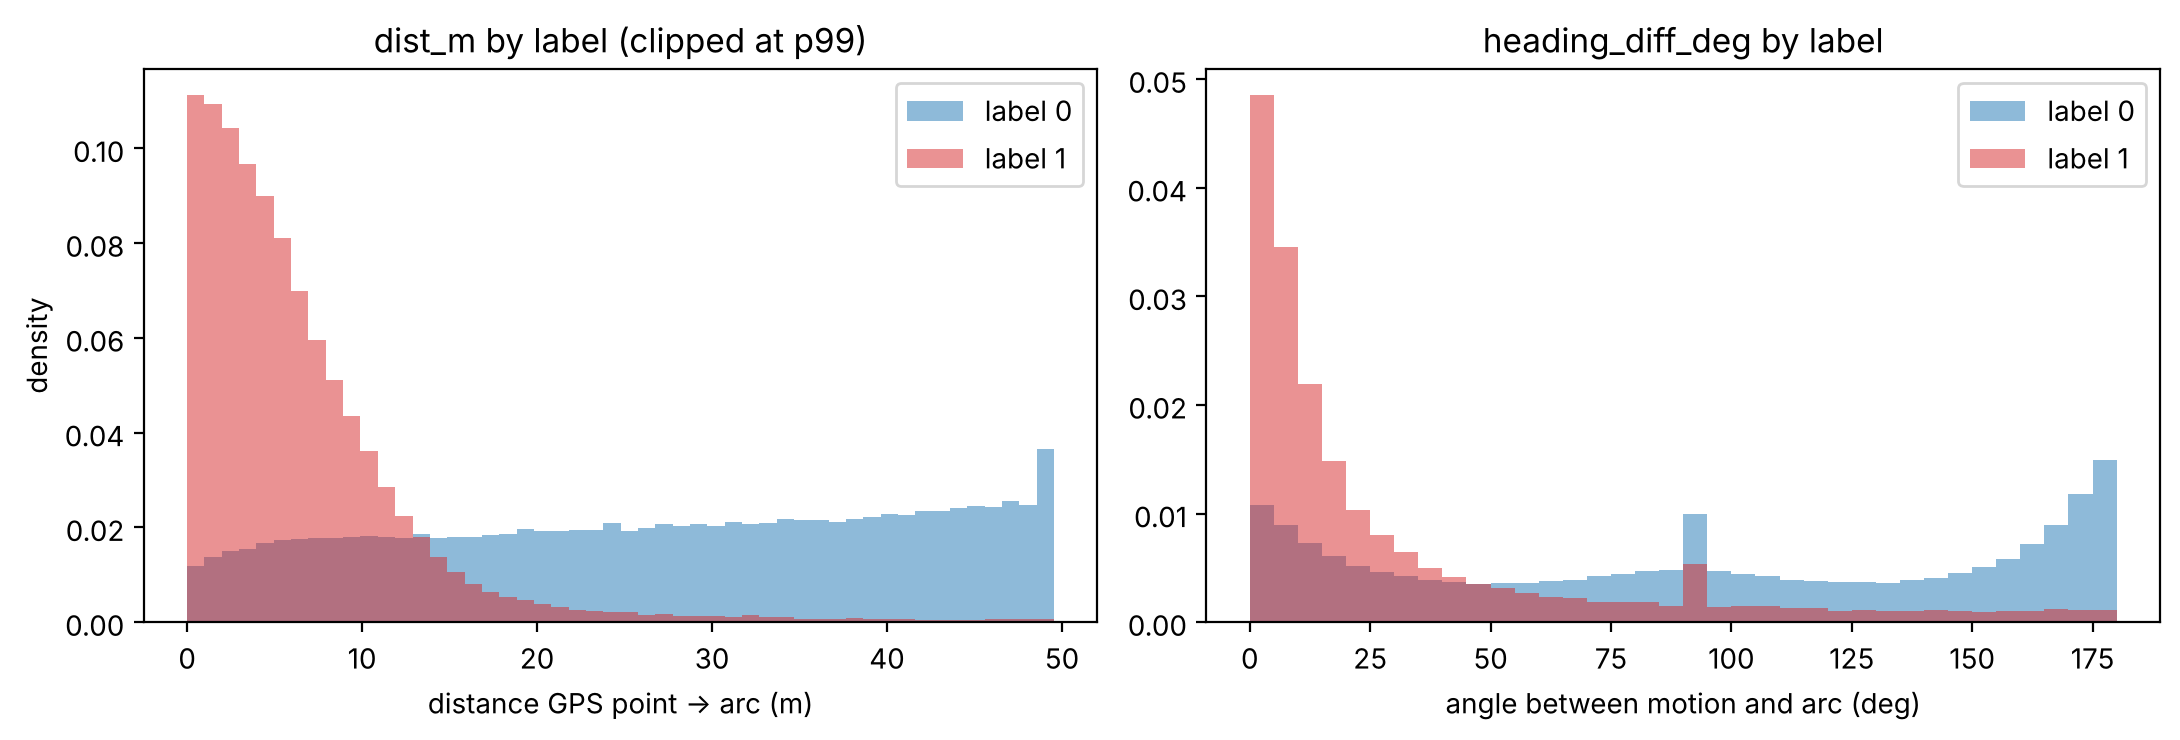

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
cap = train["dist_m"].quantile(0.99)
for lab, colr in [(0, "tab:blue"), (1, "tab:red")]:
    sub = train[train["label"] == lab]
    ax[0].hist(sub["dist_m"].clip(upper=cap), bins=50, density=True, alpha=0.5, color=colr, label=f"label {lab}")
    ax[1].hist(sub["heading_diff_deg"], bins=36, range=(0, 180), density=True, alpha=0.5, color=colr, label=f"label {lab}")
ax[0].set(title="dist_m by label (clipped at p99)", xlabel="distance GPS point -> arc (m)", ylabel="density")
ax[1].set(title="heading_diff_deg by label", xlabel="angle between motion and arc (deg)")
for a in ax: a.legend()
plt.tight_layout(); plt.savefig(FIG / "hist_dist_heading_by_label.png", dpi=150); plt.show()

## b. Spearman correlation matrix (flag |rho| > 0.9)

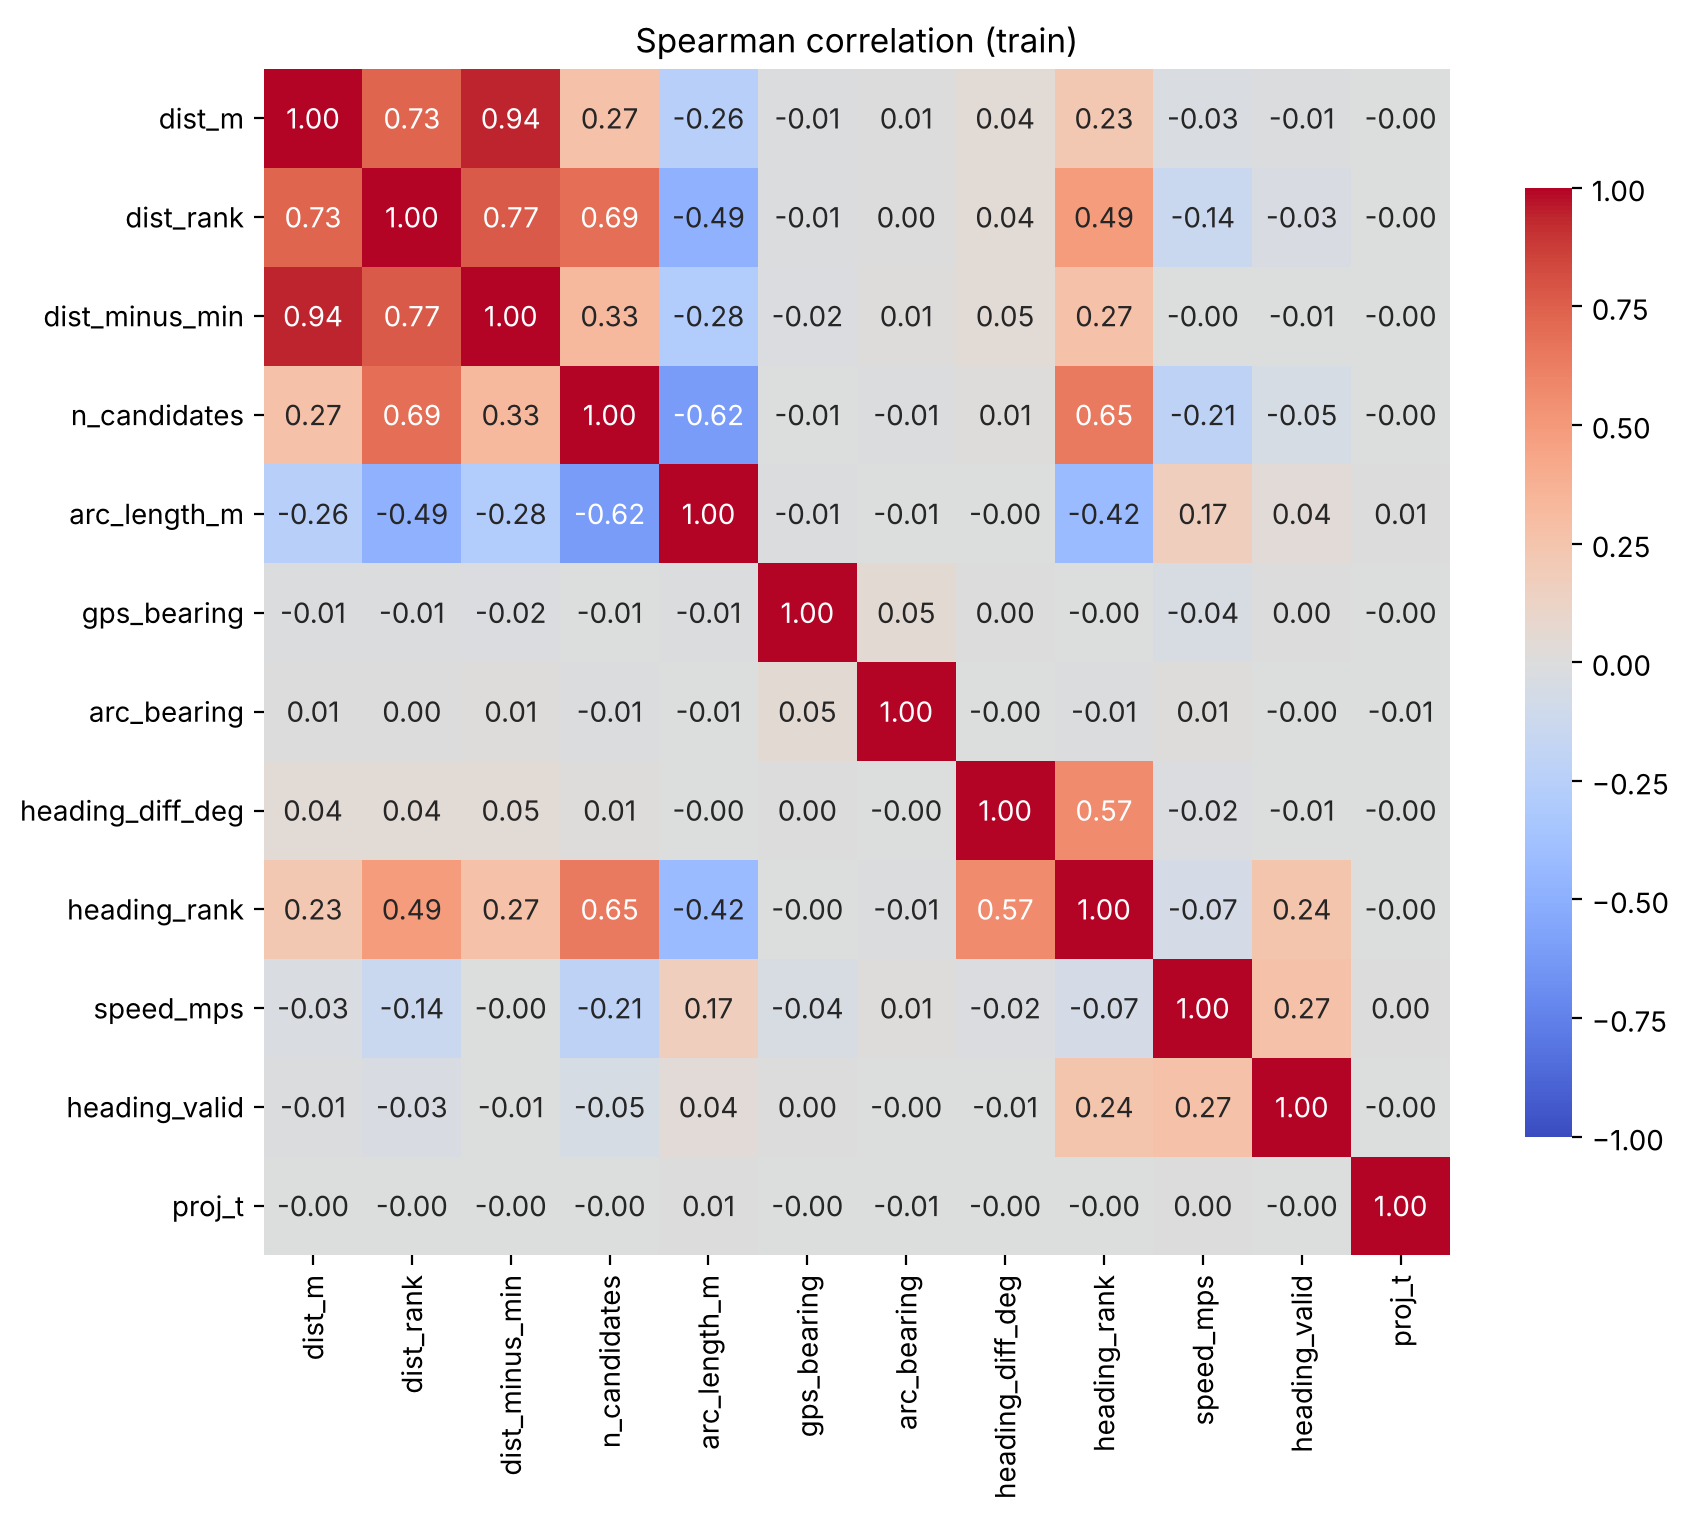

,feature_a,feature_b,spearman_rho
0,dist_m,dist_minus_min,0.943344


In [4]:
corr_src = train[FEATURES_ALL] if len(train) <= CORR_ROWS else train[FEATURES_ALL].sample(CORR_ROWS, random_state=SEED)
const = [c for c in FEATURES_ALL if corr_src[c].nunique() <= 1]
if const: print("constant columns (rho undefined, set to 0):", const)
rho = corr_src.corr(method="spearman").fillna(0.0)
_a = rho.to_numpy(copy=True); np.fill_diagonal(_a, 1.0)
rho = pd.DataFrame(_a, index=rho.index, columns=rho.columns)

plt.figure(figsize=(9, 7.5))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .8})
plt.title("Spearman correlation (train)"); plt.tight_layout()
plt.savefig(FIG / "spearman_heatmap.png", dpi=150); plt.show()

flagged = sorted(
    [(a, b, float(rho.loc[a, b])) for i, a in enumerate(FEATURES_ALL) for b in FEATURES_ALL[i + 1:] if abs(rho.loc[a, b]) > 0.9],
    key=lambda t: -abs(t[2]))
flag_df = pd.DataFrame(flagged, columns=["feature_a", "feature_b", "spearman_rho"])
flag_df.to_csv(RES / "feature_corr_flagged_pairs.csv", index=False)
flag_df

## c. Univariate scores: ANOVA F and mutual information (stratified sample)

In [5]:
X, y = sample[FEATURES_ALL], sample["label"].to_numpy()
F, p = f_classif(X, y)
mi = mutual_info_classif(X, y, discrete_features=np.array([c in DISCRETE for c in FEATURES_ALL]), random_state=SEED)
uni = pd.DataFrame({"feature": FEATURES_ALL, "f_score": np.nan_to_num(F), "mutual_info": mi})
uni.sort_values("f_score", ascending=False).round(4)

,feature,f_score,mutual_info
2,dist_minus_min,41166.4592,0.1545
0,dist_m,40440.5624,0.1063
7,heading_diff_deg,20903.0922,0.0564
1,dist_rank,13412.0009,0.1511
4,arc_length_m,11235.2159,0.0673
8,heading_rank,9099.2300,0.0657
3,n_candidates,7886.8886,0.0449
9,speed_mps,1118.5647,0.0019
6,arc_bearing,118.7011,0.0817
10,heading_valid,32.3963,0.0001


## d. Random-Forest importances (same sample) + permutation importance on a trip-grouped hold-out

* **rf_importance** = impurity importance of one RF fitted on the whole sample (can favour continuous features; treat as a rough guide).
* **perm_importance** = drop in **macro-F1** when a feature is shuffled, on a 20 % hold-out that shares **no trips** with the data the forest was fitted on.

In [6]:
RF_PARAMS = dict(n_estimators=200, max_depth=12, class_weight="balanced", n_jobs=-1, random_state=SEED)

rf_full = RandomForestClassifier(**RF_PARAMS).fit(X, y)
rf_imp = pd.Series(rf_full.feature_importances_, index=FEATURES_ALL)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, ho_idx = next(gss.split(sample, y, groups=sample["trip_id"]))
assert not set(sample.loc[tr_idx, "trip_id"]) & set(sample.loc[ho_idx, "trip_id"]), "trip leaked across the split"
rf_ho = RandomForestClassifier(**RF_PARAMS).fit(X.iloc[tr_idx], y[tr_idx])
pi = permutation_importance(rf_ho, X.iloc[ho_idx], y[ho_idx], scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=FEATURES_ALL)
perm_sd = pd.Series(pi.importances_std, index=FEATURES_ALL)

from sklearn.metrics import f1_score
print("hold-out trips:", sample.loc[ho_idx, "trip_id"].nunique(), "| hold-out macro-F1 of the RF: %.4f" % f1_score(y[ho_idx], rf_ho.predict(X.iloc[ho_idx]), average="macro"))
pd.DataFrame({"rf_importance": rf_imp, "perm_importance": perm, "perm_std": perm_sd}).sort_values("rf_importance", ascending=False).round(4)

hold-out trips: 16 | hold-out macro-F1 of the RF: 0.8630


,rf_importance,perm_importance,perm_std
dist_rank,0.2871,-0.0067,0.0006
dist_minus_min,0.2439,-0.0069,0.0016
dist_m,0.1327,-0.0005,0.0006
heading_diff_deg,0.1042,0.1226,0.0013
heading_rank,0.0708,-0.0010,0.0006
proj_t,0.0603,0.0830,0.0009
speed_mps,0.0306,0.0063,0.0011
arc_length_m,0.0290,0.0037,0.0009
n_candidates,0.0163,-0.0026,0.0005
arc_bearing,0.0154,-0.0119,0.0014


## e. Save scores and decide the final feature set

In [7]:
res = uni.merge(rf_imp.rename("rf_importance").rename_axis("feature").reset_index()).merge(
      perm.rename("perm_importance").rename_axis("feature").reset_index())
res = res[["feature", "f_score", "mutual_info", "rf_importance", "perm_importance"]]
res.to_csv(RES / "feature_selection.csv", index=False)
res.round(4)

,feature,f_score,mutual_info,rf_importance,perm_importance
0,dist_m,40440.5624,0.1063,0.1327,-0.0005
1,dist_rank,13412.0009,0.1511,0.2871,-0.0067
2,dist_minus_min,41166.4592,0.1545,0.2439,-0.0069
3,n_candidates,7886.8886,0.0449,0.0163,-0.0026
4,arc_length_m,11235.2159,0.0673,0.0290,0.0037
5,gps_bearing,0.7598,0.0005,0.0096,-0.0028
6,arc_bearing,118.7011,0.0817,0.0154,-0.0119
7,heading_diff_deg,20903.0922,0.0564,0.1042,0.1226
8,heading_rank,9099.2300,0.0657,0.0708,-0.0010
9,speed_mps,1118.5647,0.0019,0.0306,0.0063


In [8]:
# ---- decision rule (stated up front, applied mechanically) ----
# redundant : |Spearman rho| > 0.9 with a STRONGER feature (stronger = better mean rank over f_score, mutual_info, rf_importance)
# weak      : below the median of all candidate features on ALL THREE of f_score, mutual_info, rf_importance
# drop      : redundant AND weak.  perm_importance is shown for context, not used in the rule.
S = res.set_index("feature")
score_cols = ["f_score", "mutual_info", "rf_importance"]
mean_rank = S[score_cols].rank(ascending=False, method="min").mean(axis=1)      # lower = stronger
weak = (S[score_cols] < S[score_cols].median()).all(axis=1)

dropped, rows = set(), []
for a, b, r in flagged:                                                          # strongest correlations first
    if a in dropped or b in dropped:
        continue
    stronger, weaker = (a, b) if mean_rank[a] <= mean_rank[b] else (b, a)
    rows.append(dict(pair=f"{a} ~ {b}", rho=round(r, 3), stronger=stronger, weaker=weaker,
                     weaker_is_weak_on_all_three=bool(weak[weaker]), action="DROP " + weaker if weak[weaker] else "keep both"))
    if weak[weaker]:
        dropped.add(weaker)

decisions = pd.DataFrame(rows, columns=["pair", "rho", "stronger", "weaker", "weaker_is_weak_on_all_three", "action"])
display(decisions)
FINAL = [f for f in FEATURES_ALL if f not in dropped]
print("dropped:", sorted(dropped) or "nothing")
print("FINAL (%d):" % len(FINAL), FINAL)

,pair,rho,stronger,weaker,weaker_is_weak_on_all_three,action
0,dist_m ~ dist_minus_min,0.943,dist_minus_min,dist_m,False,keep both


dropped: nothing
FINAL (12): ['dist_m', 'dist_rank', 'dist_minus_min', 'n_candidates', 'arc_length_m', 'gps_bearing', 'arc_bearing', 'heading_diff_deg', 'heading_rank', 'speed_mps', 'heading_valid', 'proj_t']


In [9]:
assert_feature_list_leak_free(FINAL)
out = ROOT / "src" / "features" / "feature_list.py"
out.write_text(
    "# Final model features. Auto-written by notebooks/03_feature_selection.ipynb from the TRAIN table only.\n"
    "# Rule: drop a feature only if |Spearman rho| > 0.9 with a stronger feature AND it is below the median on\n"
    "# f_score, mutual_info and rf_importance. Sample seed 42, <= 200k stratified rows.\n\n"
    "FEATURES = " + json.dumps(FINAL, indent=4) + "\n\n"
    "DROPPED = " + json.dumps(sorted(dropped)) + "\n"
)
print(out.read_text())

# Final model features. Auto-written by notebooks/03_feature_selection.ipynb from the TRAIN table only.
# Rule: drop a feature only if |Spearman rho| > 0.9 with a stronger feature AND it is below the median on
# f_score, mutual_info and rf_importance. Sample seed 42, <= 200k stratified rows.

FEATURES = [
    "dist_m",
    "dist_rank",
    "dist_minus_min",
    "n_candidates",
    "arc_length_m",
    "gps_bearing",
    "arc_bearing",
    "heading_diff_deg",
    "heading_rank",
    "speed_mps",
    "heading_valid",
    "proj_t"
]

DROPPED = []



**Reading the results (for the 11:30 presentation).**
`speed_mps`, `heading_valid` and `n_candidates` have the *same value for every candidate of one GPS point*, so on their own they cannot tell which candidate is right; at best they shift how likely any candidate is to be positive, and they help only in combination with candidate-specific features (e.g. `heading_valid` switches `heading_diff_deg` on or off). Expect weak univariate scores for them - that is not the same as useless inside a tree model.
Fill the numbers in `results/feature_selection.md` from the table in section e.